# Use the PV-HLCA model

Change technology assumptions, create independent supply-chain scenarios and compare their outcomes. This notebook starts from a reusable prepared model; [database preparation](../docs/database-preparation.md) and [paper reproduction](../paper/README.md) are documented separately.

If no prepared model is available, the build cell automatically downloads the fixed Zenodo source (1.78 GB), verifies and converts it, then prepares the model. Later runs reuse the local bundle. See [installation and offline use](../docs/installation.md).

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from pv_hlca import PVModel, ModelParameters, Scenario

ROOT = Path.cwd()
if not (ROOT / "config").is_dir():
    ROOT = ROOT.parent
prepared_path = ROOT / "models" / "prepared"

## Choose technology assumptions

These assumptions apply to every scenario in this experiment. Fractions are entered as 0.22 (22%) and 0.005 (0.5% per year). Build another model to compare a different technology specification.

In [2]:
parameters = ModelParameters(
    capacity_factor="OWID",
    module_efficiency=0.22,
    degradation_rate=0.005,
    lci_variant="IEA",
)
model = PVModel.build(
    parameters, prepared_path=prepared_path,
    source_path=ROOT / "models" / "source-18744457",
)
print("Model loaded:", len(model.db.get_index("Region")), "regions")

Model loaded: 22 regions


## Define independent scenarios

Both scenarios start from the same observed-trade baseline. The first changes EU module sourcing; the second changes module and cell sourcing. The total use of each commodity by each activity is conserved. Other foreign suppliers retain their relative shares.

In [3]:
model.add_scenario(Scenario(
    "eu_modules_60",
    domestic_shares={"EU27": {"PV modules": 0.60}},
))
model.add_scenario(Scenario(
    "eu_modules_and_cells",
    domestic_shares={"EU27": {"PV modules": 0.60, "Cells": 0.40}},
))
print("Scenarios ready:", ", ".join(model.scenario_specs))

Scenarios ready: eu_modules_60, eu_modules_and_cells


## Compare footprints and prices

The full tables cover all model regions. Here we display EU27 and China. Economic totals and employment are available in the same result dictionary.

In [4]:
tables = model.results()
footprints = tables["footprints"].pivot(
    index="region", columns="scenario", values="footprint_gkwh"
)
prices = tables["prices"].pivot(
    index="region", columns="scenario", values="price_eur_kwh"
)
display(footprints.loc[["EU27", "CN"]])
display(prices.loc[["EU27", "CN"]])

scenario,baseline,eu_modules_60,eu_modules_and_cells
region,,,
EU27,49.795744,45.571895,44.839423
CN,63.560903,63.560541,63.560478


scenario,baseline,eu_modules_60,eu_modules_and_cells
region,,,
EU27,0.064015,0.063515,0.065315
CN,0.059040,0.059040,0.059040


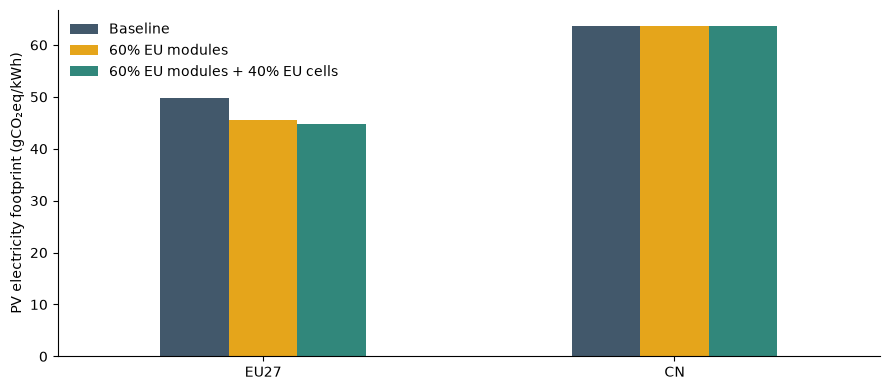

In [5]:
order = ["baseline", "eu_modules_60", "eu_modules_and_cells"]
ax = footprints.loc[["EU27", "CN"], order].plot.bar(
    figsize=(9, 4), color=["#42586b", "#e5a51b", "#31877b"], rot=0
)
ax.set_ylabel("PV electricity footprint (gCO₂eq/kWh)")
ax.set_xlabel("")
ax.legend(["Baseline", "60% EU modules", "60% EU modules + 40% EU cells"], frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Inspect the model with MARIO

The underlying MARIO Database remains available. Direct database edits support more advanced experiments; record those edits in your analysis because they are outside the YAML scenario definitions.

In [6]:
db = model.db
print(db.scenarios)
use = db.query(matrices="u", scenarios="baseline")
display(use.loc[[("EU27", "Commodity", "PV modules"),
                 ("CN", "Commodity", "PV modules")],
                [("EU27", "Activity", "Solar Power Plant")]])

['baseline', 'domestic', 'eu_modules_60', 'eu_modules_and_cells']


,,Region,EU27
,,Level,Activity
,,Item,Solar Power Plant
Region,Level,Item,
EU27,Commodity,PV modules,1.571785
CN,Commodity,PV modules,37.937381


## Save the experiment

The six tables and run manifest record the selected technology assumptions, scenario definitions and prepared-model provenance. This cell explicitly replaces a previous export of this notebook experiment.

In [7]:
output = ROOT / "outputs" / "notebook_example"
model.export(output, overwrite=True)
print("Saved results to outputs/notebook_example/")

Saved results to outputs/notebook_example/


Next: [define custom electricity mixes and explicit suppliers](../docs/scenarios.md), [run YAML experiments](../docs/use-the-model.md), or [reproduce the published study](../paper/README.md).